# The cosine schedule at full training, and a copying test with a calibrated distance

Stage 1 trained a denoising diffusion model on 5,777 planes of streamwise velocity from a turbulent channel flow, with a linear noise schedule, and its schedule experiment showed, on 10-epoch models, that a cosine schedule halves the error of the generated mean profile. Stage 2 measured the base model's samples against 577 held-out fields and found a nearly flat mean profile, and a nearest-training-field distance that said the samples are not copies but left the question of what distance a genuinely new field of this flow has from the training set, because the random split puts other planes of the same snapshot into training.

- **Part (a): the cosine schedule at 40 epochs.** Stage 1's denoiser (same architecture, 508,785 weights) trained with the cosine schedule at T = 200 for the full 40 epochs, with seeds 0, 1 and 2, and every statistic of Stage 2 computed against the same 577 held-out fields, next to Stage 1's base model (linear schedule, its saved denoiser), the Gaussian baseline and the training fields. One figure: mean and RMS profiles.
- **Part (b): a calibrated copying test.** For each held-out field, the RMS distance to the nearest training field from a **different snapshot**, beside Stage 2's number that allowed same-snapshot neighbours; then the same distance for the cosine model's samples. No training in this part.

Same padding, normalisation and random split as Stage 1, so the held-out fields are the same 577. Apple GPU, one training at a time. Each cosine training takes about 22 minutes; I repeat it with three seeds because the base model's seed spread was never measured, and measuring it is part of the experiment. A difference is called an effect only when it is larger than the seed range; values that span orders of magnitude are given as median and range.

# Stage 3 — The cosine schedule at full training, and a copying test with a calibrated distance

**Portfolio project: a diffusion model for channel-flow fields, held to held-out statistics.**

Stage 1's schedule experiment showed on 10-epoch models that a cosine noise schedule halves the error of the generated mean profile; Stage 2 found the base model's samples far from copies but left open what distance a genuinely new field of this flow has from the training set, because the random split puts other planes of the same snapshot into training. Part (a) trains the Stage 1 denoiser with the cosine schedule for the full 40 epochs, three model seeds, and scores every Stage 2 statistic against the same 577 held-out fields, next to the base model (linear schedule, its saved denoiser), the Gaussian baseline and the training fields. Part (b) computes, for every held-out field, the distance to the nearest training field from a different snapshot, beside Stage 2's number, and places the samples against it.

**What it shows.** At 40 epochs the cosine schedule cuts the mean-profile error from 0.19 to 0.068 (range 0.043–0.084 over three seeds), beyond the seed range, and the generated mean profile follows the real one from the walls to the centre; but it does not close the gap to a real ensemble (0.0007), and the RMS profile is now too high everywhere (0.052 against 0.030). Two-point correlation and the probability density of u improve beyond the seed range; the spectra do not. A ten-step DDIM sampler loses the mean-profile gain. A new real field of this flow lies 0.109 (range 0.090–0.124) from the training set once same-snapshot planes are excluded, against 0.026 when they count; the cosine model's samples sit at 0.169 and the base model's at 0.229: not copies, still farther from the training set than a new real field, and the cosine model's are closer and more diverse (450 distinct nearest training fields in 768 samples, against 13 in Stage 2).

**How it connects.** It reads the planes from `../release_assets/u_yx_planes_h5/` with Stage 1's padding, normalisation and split, copies the denoiser, the training loop, the cosine schedule and the samplers of Stage 1 and the statistics of Stage 2, loads Stage 1's saved denoiser as the base model, and reads Stage 2's result tables and device timings. With the cosine schedule the last noise level is practically pure noise (ᾱ_T ≈ 6e-8), so the samplers use the clipped clean-field form of the DDPM update, as Stage 1's schedule experiment did; the base model is sampled both ways to show the clipping changes nothing for the linear schedule.

**About the outputs.** The outputs below come from my single run (Apple M3 Max, Apple GPU, 2026-10-14, 62 minutes; each cosine training 18.5–19.2 minutes, repeated with three seeds because the base model's seed spread was never measured). Afterwards I changed only text for this repository: this cell and the paths cell, and the path lines (planes from `../release_assets/`, the base denoiser from `../models/01_diffusion_channel_flow/`, Stage 2 tables from `../results/02_field_statistics_and_memorisation/`, tables and figures to `../results/03_cosine_schedule_and_calibrated_copying/`, the seed-0 cosine denoiser to `../models/03_cosine_schedule_and_calibrated_copying/`). The seed-1 and seed-2 denoisers stayed with my run.

In [ ]:
# Paths in the repository layout (run this notebook from notebooks/)
from pathlib import Path
DATA_DIR = Path("../release_assets/u_yx_planes_h5")                                    # the 5,777 planes (release file of the unet-turbulent-fields repository)
BASE_MODEL = Path("../models/01_diffusion_channel_flow/diffusion_denoiser.keras")       # Stage 1's base denoiser (linear schedule, 40 epochs)
EARLIER_STAGE = Path("../results/02_field_statistics_and_memorisation")                 # Stage 2's result tables (read only for the comparison)
TIMING_DIR = Path("../results/02_field_statistics_and_memorisation")                    # device_timing_cpu.csv, device_timing_gpu.csv
RES = Path("../results/03_cosine_schedule_and_calibrated_copying"); RES.mkdir(parents=True, exist_ok=True)
MOD = Path("../models/03_cosine_schedule_and_calibrated_copying"); MOD.mkdir(parents=True, exist_ok=True)
print("planes:", len(sorted(DATA_DIR.glob("P125_83pi.*.h5"))), "| base model present:", BASE_MODEL.exists(), "| Stage 2 tables present:", (EARLIER_STAGE / "a_statistics_table.csv").exists())

In [2]:
import json, time, platform
import h5py
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

print("TensorFlow", tf.__version__, "| Keras", tf.keras.__version__, "| GPUs:", tf.config.list_physical_devices("GPU"), "|", platform.machine())
# Device from the step timing of Stage 2 (one training step inside model.fit, batch 16, 208 × 384 fields,
# median of 30 after 10 warm-up steps); the environment is unchanged since then
timing = pd.concat([pd.read_csv(TIMING_DIR / "device_timing_cpu.csv"), pd.read_csv(TIMING_DIR / "device_timing_gpu.csv")])
tt = timing.pivot(index="network", columns="device", values="median_ms"); print(tt.round(1))
row = [r for r in tt.index if r.startswith("denoiser")][0]
assert tt.loc[row, "gpu"] < tt.loc[row, "cpu"]; DEVICE = "/GPU:0"
print("device for every network:", DEVICE)
T_START = time.time()

TensorFlow 2.18.1 | Keras 3.6.0 | GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')] | arm64
device                                           cpu   gpu
network                                                   
conditional denoiser, 2 input channels (Ex 2)  596.8  91.2
denoiser, 3-level U-Net (16 filters)           588.6  87.1
device for every network: /GPU:0


## Data, padding, normalisation and split, exactly as in Stage 1

Every plane is padded from 201 to 208 rows by repeating the last row (so the U-Net's three halvings divide evenly), normalised with the global mean and standard deviation of all 5,777 fields, and split with the same random permutation (seed 0): 5,200 training fields, 577 held-out. The snapshot number of every plane comes from its file name, so that part (b) can exclude neighbours from the same snapshot.

In [3]:
# Copied from Stage 1 (data cells) and Stage 2 (held-out and training arrays), unchanged in substance
files = sorted(DATA_DIR.glob("P125_83pi.*.h5"))
with h5py.File(files[0], "r") as f: n_y_raw, n_x = f["u"].shape; y_grid = f["y"][:]
pad = 16 - (n_y_raw % 16) if n_y_raw % 16 else 0; n_y_padded = n_y_raw + pad
fields = np.zeros((len(files), n_y_padded, n_x, 1), np.float32)
for i, fp in enumerate(files):
    with h5py.File(fp, "r") as f: u = f["u"][:]
    fields[i, :, :, 0] = np.pad(u, ((0, pad), (0, 0)), mode="edge") if pad else u
data_mean = fields.mean(); data_std = fields.std() + 1e-8
fields_norm = (fields - data_mean) / data_std
perm = np.random.default_rng(0).permutation(len(fields)); n_val = max(1, int(0.1 * len(fields)))
val_idx, trn_idx = perm[:n_val], perm[n_val:]
fields_trn = fields_norm[trn_idx]
held = fields[val_idx, :n_y_raw, :, 0]; train = fields[trn_idx, :n_y_raw, :, 0]
snap = np.array([int(fp.name.split(".")[1]) for fp in files]); plane = np.array([int(fp.name.split(".")[2]) for fp in files])
print("fields", fields.shape, "| training", fields_trn.shape, "| held-out", held.shape, "| data_mean, data_std:", data_mean, data_std)
print(f"snapshots: {len(np.unique(snap))} with {len(np.unique(plane))} planes each; held-out fields whose snapshot also has training planes: "
      f"{int(np.isin(snap[val_idx], snap[trn_idx]).sum())} of {n_val}")
batch_size = 16; steps_per_epoch = max(1, fields_trn.shape[0] // batch_size)
T = 200; beta_linear = np.linspace(1e-4, 0.02, T).astype(np.float32)

fields (5777, 208, 384, 1) | training (5200, 208, 384, 1) | held-out (577, 201, 384) | data_mean, data_std: 0.78406733 0.34096804
snapshots: 107 with 60 planes each; held-out fields whose snapshot also has training planes: 577 of 577


## The denoiser and the two schedules

The time-conditioned U-Net of Stage 1, copied below unchanged: a sinusoidal embedding of the timestep, added to every convolutional block, three encoder blocks, a bottleneck and three decoder blocks with 16 base filters. The **linear schedule** raises β from 1e-4 to 0.02 over 200 steps and leaves ᾱ_T = 0.132, so the noisiest training input still carries 36 % of the signal while sampling starts from pure noise. The **cosine schedule** (Stage 1's schedule experiment, copied) sets ᾱ(t) = cos²((t/T + s)/(1 + s) · π/2) / cos²(s/(1 + s) · π/2) with s = 0.008 and clips β at 0.999, so ᾱ_T is practically zero and the training inputs reach pure noise.

In [4]:
# Copied unchanged from Stage 1 (denoiser cells)

def sinusoidal_embedding(t, dim=64):
    """t: float tensor, shape (batch,). Returns shape (batch, dim)."""
    half = dim // 2
    freqs = tf.exp(-tf.math.log(10000.0) * tf.range(half, dtype=tf.float32) / half)
    args = tf.cast(t[:, None], tf.float32) * freqs[None, :]
    return tf.concat([tf.sin(args), tf.cos(args)], axis=-1)

def conv_block_t(x, t_emb, filters, kernel_size=3, activation="relu", padding="same"):
    x = tf.keras.layers.Conv2D(filters, kernel_size, padding=padding, kernel_initializer="he_normal")(x)
    t_proj = tf.keras.layers.Dense(filters)(t_emb)
    t_proj = tf.keras.layers.Reshape((1, 1, filters))(t_proj)
    x = tf.keras.layers.Add()([x, t_proj])
    x = tf.keras.layers.Activation(activation)(x)
    x = tf.keras.layers.Conv2D(filters, kernel_size, activation=activation, padding=padding, kernel_initializer="he_normal")(x)
    return x

def encoder_block_t(x, t_emb, filters):
    skip = conv_block_t(x, t_emb, filters)
    down = tf.keras.layers.MaxPooling2D(pool_size=2)(skip)
    return skip, down

def decoder_block_t(x, skip, t_emb, filters):
    x = tf.keras.layers.Conv2DTranspose(filters, kernel_size=2, strides=2, padding="same")(x)
    x = tf.keras.layers.Concatenate()([x, skip])
    x = conv_block_t(x, t_emb, filters)
    return x

def create_denoiser(input_shape, base_filters=16, time_emb_dim=64):
    image_input = tf.keras.layers.Input(shape=input_shape, name="noisy_field")
    t_input = tf.keras.layers.Input(shape=(), name="timestep")
    t_emb = tf.keras.layers.Lambda(lambda t: sinusoidal_embedding(t, dim=time_emb_dim))(t_input)
    t_emb = tf.keras.layers.Dense(time_emb_dim, activation="relu")(t_emb)
    skip1, x = encoder_block_t(image_input, t_emb, base_filters)
    skip2, x = encoder_block_t(x, t_emb, base_filters * 2)
    skip3, x = encoder_block_t(x, t_emb, base_filters * 4)
    x = conv_block_t(x, t_emb, base_filters * 8)
    x = decoder_block_t(x, skip3, t_emb, base_filters * 4)
    x = decoder_block_t(x, skip2, t_emb, base_filters * 2)
    x = decoder_block_t(x, skip1, t_emb, base_filters)
    noise_pred = tf.keras.layers.Conv2D(1, kernel_size=1, activation="linear")(x)
    return tf.keras.Model([image_input, t_input], noise_pred, name="Denoiser")

# Copied unchanged from Stage 1 (schedule exercise)
def cosine_beta(T_, s=0.008):
    tt = np.arange(T_ + 1) / T_
    f = np.cos((tt + s) / (1 + s) * np.pi / 2) ** 2
    ab = f / f[0]
    return np.clip(1.0 - ab[1:] / ab[:-1], 0.0, 0.999).astype(np.float32)

beta_cosine = cosine_beta(T)
input_shape = (n_y_padded, n_x, 1)
print("alpha_bar at the last step: linear", float(np.cumprod(1 - beta_linear)[-1]), "| cosine", float(np.cumprod(1 - beta_cosine.astype(np.float64))[-1]))
print("denoiser parameters:", create_denoiser(input_shape, base_filters=16).count_params())

alpha_bar at the last step: linear 0.132182776927948 | cosine 6.07172144859874e-08


2026-10-14 20:54:15.079464: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M3 Max
2026-10-14 20:54:15.081348: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 48.00 GB
2026-10-14 20:54:15.081376: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 18.72 GB
I0000 00:00:1792025655.081398 57605531 pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
I0000 00:00:1792025655.081435 57605531 pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


denoiser parameters: 508785


## Training and sampling

**Training** is Stage 1's loop: Adam at 2e-4, batch 16, 325 steps per epoch, 40 epochs; each step draws a timestep per field and Gaussian noise, forms the noisy field, and minimises the mean squared error between the noise and the network's prediction. The seed sets the initial weights, the batch order, the timesteps and the noise.

**Sampling** follows Stage 2: DDPM with all 200 steps, and deterministic DDIM with 10 steps. With the cosine schedule the last step has ᾱ ≈ 0, and Stage 1's plain update divides by √α_T ≈ 0.03, so for the cosine model I write the same DDPM mean through the estimate of the clean field, clipped to the range of the normalised training fields, as Stage 1's schedule experiment did; DDIM clips the same estimate. The base model is sampled both ways, so the clipping's own effect is visible. Samples are returned in physical units, cropped to the 201 real rows.

In [5]:
# Training loop: copied from Stage 1 (its custom loop and the schedule exercise's trainer), seeds added
def train_denoiser(model, beta_, epochs, seed, lr=2e-4, label=""):
    ab = np.cumprod(1.0 - np.asarray(beta_, np.float64)).astype(np.float32)
    sab_c, somab_c, T_ = tf.constant(np.sqrt(ab)), tf.constant(np.sqrt(1.0 - ab)), len(beta_)
    opt = tf.keras.optimizers.Adam(learning_rate=lr)

    @tf.function
    def step(x0):
        bn = tf.shape(x0)[0]
        t_idx = tf.random.uniform((bn,), minval=0, maxval=T_, dtype=tf.int32)
        noise = tf.random.normal(tf.shape(x0))
        xt = tf.gather(sab_c, t_idx)[:, None, None, None] * x0 + tf.gather(somab_c, t_idx)[:, None, None, None] * noise
        with tf.GradientTape() as tape:
            pred = model([xt, tf.cast(t_idx, tf.float32)], training=True)
            loss = tf.reduce_mean(tf.square(noise - pred))
        grads = tape.gradient(loss, model.trainable_weights)
        opt.apply_gradients(zip(grads, model.trainable_weights))
        return loss

    rng = np.random.default_rng(seed); tf.random.set_seed(seed)
    hist, t0 = [], time.time()
    for ep in range(epochs):
        p = rng.permutation(fields_trn.shape[0]); ls = []
        for k in range(steps_per_epoch):
            bi = p[k * batch_size:(k + 1) * batch_size]
            ls.append(float(step(fields_trn[bi])))
        hist.append(float(np.mean(ls)))
        if (ep + 1) % 5 == 0 or ep == 0: print(f"[{label}] epoch {ep + 1}/{epochs} loss={hist[-1]:.4f} ({(time.time() - t0) / 60:.1f} min)", flush=True)
    return hist, time.time() - t0

# Samplers: copied from Stage 2 (DDPM update of Stage 1; deterministic DDIM), with the clipped form of the schedule exercise
fn_cache = {}
def call_model(model, x, t):
    f = fn_cache.get(id(model))
    if f is None:
        f = tf.function(lambda a, b: model([a, b], training=False), reduce_retracing=True); fn_cache[id(model)] = f
    return f(x, t)

def sample(model, beta_, n, seed, method="ddpm", steps=10, x0_clip=None, chunk=64):
    b = np.asarray(beta_, np.float64); a = 1.0 - b; ab = np.cumprod(a); T_ = len(b); gen = tf.random.Generator.from_seed(seed); out = []
    for s in range(0, n, chunk):
        m = min(chunk, n - s); x = gen.normal((m, n_y_padded, n_x, 1))
        if method == "ddpm":
            for t in reversed(range(T_)):
                eps = call_model(model, x, tf.fill((m,), float(t)))
                if x0_clip is None:      # Stage 1's update
                    mean = (x - float(b[t] / np.sqrt(1 - ab[t])) * eps) / float(np.sqrt(a[t]))
                else:                    # the same mean written through a clipped estimate of the clean field
                    x0 = tf.clip_by_value((x - float(np.sqrt(1 - ab[t])) * eps) / float(np.sqrt(ab[t])), *x0_clip)
                    abp = ab[t - 1] if t > 0 else 1.0
                    mean = float(np.sqrt(abp) * b[t] / (1 - ab[t])) * x0 + float(np.sqrt(a[t]) * (1 - abp) / (1 - ab[t])) * x
                x = mean + float(np.sqrt(b[t])) * gen.normal(tf.shape(x)) if t > 0 else mean
        else:
            ts = np.unique(np.linspace(0, T_ - 1, steps).round().astype(int))[::-1]
            for i, t in enumerate(ts):
                eps = call_model(model, x, tf.fill((m,), float(t)))
                x0 = (x - float(np.sqrt(1 - ab[t])) * eps) / float(np.sqrt(ab[t]))
                if x0_clip is not None: x0 = tf.clip_by_value(x0, *x0_clip)
                abp = ab[ts[i + 1]] if i + 1 < len(ts) else 1.0
                x = float(np.sqrt(abp)) * x0 + float(np.sqrt(1 - abp)) * eps
        out.append(x.numpy()[:, :n_y_raw, :, 0] * data_std + data_mean)
    return np.concatenate(out)

CLIP = (float(fields_trn.min()), float(fields_trn.max()))
print("clip range of the clean-field estimate (normalised units):", CLIP)

clip range of the clean-field estimate (normalised units): (-2.3800928592681885, 1.4700335264205933)


## The statistics of Stage 2

All against the 577 held-out fields: mean and RMS profile errors (mean absolute difference over the 201 rows); the log-spectral distance over streamwise modes 1 to 64 at y+ ≈ 15 (row 23), at the centre (row 100) and over all rows; the small-scale energy ratio (modes 65 to 192) at y+ ≈ 15; the streamwise two-point correlation at both rows (its mean absolute error and the separation where it first drops below 0.5); and the 1-Wasserstein distance between the histograms of u at y+ ≈ 15. Wall distance y+ uses the nominal friction Reynolds number 125.

In [6]:
# Copied unchanged from Stage 2 (statistics cell)
half = (y_grid[-1] - y_grid[0]) / 2; yp_bot = (y_grid - y_grid[0]) / half * 125.0
j15 = int(np.argmin(np.abs(yp_bot - 15))); jc = n_y_raw // 2; Lx = 8 * np.pi; dx = Lx / n_x
print(f"y+ 15 row {j15} (y+ {yp_bot[j15]:.1f}); centre row {jc}")

def spectrum(u):
    up = u - u.mean(axis=(0, 2), keepdims=True); acc = np.zeros((u.shape[1], n_x // 2 + 1))
    for s in range(0, len(u), 64): acc += (np.abs(np.fft.rfft(up[s:s + 64], axis=-1)) ** 2).sum(0)
    return acc / len(u) / n_x ** 2
def corr_x(u, j):
    up = u[:, j, :] - u[:, j, :].mean(); P = (np.abs(np.fft.rfft(up, axis=-1)) ** 2).mean(0); R = np.fft.irfft(P, n=n_x); return (R / R[0])[: n_x // 2 + 1]
def first_below(R, lv=0.5):
    k = np.where(R < lv)[0]; return (k[0] if len(k) else len(R)) * dx
BINS = np.linspace(min(held[:, j15].min(), train[:, j15].min()) - 0.05, max(held[:, j15].max(), train[:, j15].max()) + 0.05, 61)
def pdf(u): h, _ = np.histogram(u[:, j15, :].ravel(), bins=BINS, density=True); return h

REF = dict(mean=held.mean(axis=(0, 2)), rms=held.std(axis=(0, 2)), E=spectrum(held), R15=corr_x(held, j15), Rc=corr_x(held, jc), pdf=pdf(held))
KMAX = 64
def stats(u):
    E = spectrum(u)
    def lsd(rows, k1=1, k2=KMAX): return float(np.sqrt(np.mean(np.log10(E[rows][:, k1:k2 + 1].mean(0) / REF["E"][rows][:, k1:k2 + 1].mean(0)) ** 2)))
    R15, Rc = corr_x(u, j15), corr_x(u, jc); p = pdf(u)
    w1 = float(np.sum(np.abs(np.cumsum(p) - np.cumsum(REF["pdf"]))) * np.diff(BINS)[0] ** 2)
    return dict(mean_profile_mae=float(np.mean(np.abs(u.mean(axis=(0, 2)) - REF["mean"]))), rms_profile_mae=float(np.mean(np.abs(u.std(axis=(0, 2)) - REF["rms"]))),
                spectral_distance_y15=lsd([j15]), spectral_distance_centre=lsd([jc]), spectral_distance_all_rows=lsd(np.arange(n_y_raw)),
                small_scale_energy_ratio_y15=float(E[j15, KMAX + 1:].mean() / REF["E"][j15, KMAX + 1:].mean()),
                corr_length_y15=first_below(R15), corr_length_centre=first_below(Rc), corr_mae_y15=float(np.mean(np.abs(R15 - REF["R15"]))),
                corr_mae_centre=float(np.mean(np.abs(Rc - REF["Rc"]))), pdf_wasserstein_y15=w1), dict(mean=u.mean(axis=(0, 2)), rms=u.std(axis=(0, 2)))

rows, curves, samples = [], {}, {}
def record(name, seed, u, **extra):
    r, c = stats(u); rows.append(dict(ensemble=name, seed=seed, n=len(u), **extra, **r)); curves[(name, seed)] = c; return r

y+ 15 row 23 (y+ 15.4); centre row 100


## Reference rows: real fields, Gaussian baseline, the base model

The training fields are scored against the held-out fields as the real-to-real reference. The Gaussian baseline draws independent pixels with the training fields' mean and RMS profiles (256 fields per seed). The base model (linear schedule, Stage 1's saved denoiser, one training) is sampled with Stage 2's DDPM sampler and with the clipped one, 256 samples each, seed 0.

In [7]:
record("training fields (real)", -1, train); record("held-out fields (real)", -1, held)
mp_tr, sd_tr = train.mean(axis=(0, 2)), train.std(axis=(0, 2))
for seed in (0, 1, 2):
    gb = (mp_tr[None, :, None] + sd_tr[None, :, None] * np.random.default_rng(1000 + seed).standard_normal((256, n_y_raw, n_x))).astype(np.float32)
    record("Gaussian baseline (independent pixels)", seed, gb)

with tf.device(DEVICE):
    base = create_denoiser(input_shape, base_filters=16); base.load_weights(str(BASE_MODEL))
    _ = call_model(base, tf.zeros((64, n_y_padded, n_x, 1)), tf.zeros((64,)))
    for name, kw in (("base model, linear, DDPM 200", dict(method="ddpm")), ("base model, linear, DDPM 200 clipped", dict(method="ddpm", x0_clip=CLIP)),
                     ("base model, linear, DDIM 10", dict(method="ddim", steps=10)), ("base model, linear, DDIM 10 clipped", dict(method="ddim", steps=10, x0_clip=CLIP))):
        t0 = time.time(); g = sample(base, beta_linear, 256, 0, **kw); secs = time.time() - t0; samples[(name, 0)] = g
        r = record(name, 0, g, sample_s=secs, model_seed=-1)
        print(f"{name}: {secs:.0f} s; mean-profile MAE {r['mean_profile_mae']:.4f}, RMS-profile MAE {r['rms_profile_mae']:.4f}, spectral distance y+15 {r['spectral_distance_y15']:.3f}", flush=True)

2026-10-14 20:54:19.964015: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


base model, linear, DDPM 200: 62 s; mean-profile MAE 0.1925, RMS-profile MAE 0.0302, spectral distance y+15 0.441


base model, linear, DDPM 200 clipped: 65 s; mean-profile MAE 0.1925, RMS-profile MAE 0.0302, spectral distance y+15 0.441


base model, linear, DDIM 10: 3 s; mean-profile MAE 0.2154, RMS-profile MAE 0.0316, spectral distance y+15 0.415


base model, linear, DDIM 10 clipped: 3 s; mean-profile MAE 0.2152, RMS-profile MAE 0.0308, spectral distance y+15 0.419


## Part (a): the cosine schedule at 40 epochs, three seeds

One cell per seed. Each trains the denoiser from scratch with the cosine schedule for 40 epochs, saves the model and its loss history, then draws 256 samples by clipped DDPM with 200 steps and 256 by clipped DDIM with 10 steps (sampling seed = model seed) and records every statistic.

In [8]:
loss_hist = {}
def run_cosine_seed(seed):
    tf.keras.backend.clear_session(); fn_cache.clear(); tf.keras.utils.set_random_seed(seed)
    with tf.device(DEVICE):
        m = create_denoiser(input_shape, base_filters=16)
        hist, secs = train_denoiser(m, beta_cosine, 40, seed, label=f"cosine T=200 seed {seed}")
        m.save(MOD / f"cosine_denoiser_seed{seed}.keras"); loss_hist[seed] = hist
        pd.DataFrame(dict(epoch=np.arange(1, len(hist) + 1), loss=hist)).to_csv(RES / f"a_loss_cosine_seed{seed}.csv", index=False)
        _ = call_model(m, tf.zeros((64, n_y_padded, n_x, 1)), tf.zeros((64,)))
        for name, kw in (("cosine, DDPM 200 clipped", dict(method="ddpm", x0_clip=CLIP)), ("cosine, DDIM 10 clipped", dict(method="ddim", steps=10, x0_clip=CLIP))):
            t0 = time.time(); g = sample(m, beta_cosine, 256, seed, **kw); ss = time.time() - t0; samples[(name, seed)] = g
            r = record(name, seed, g, sample_s=ss, model_seed=seed, train_min=secs / 60, final_loss=hist[-1])
            print(f"seed {seed} {name}: {ss:.0f} s; mean-profile MAE {r['mean_profile_mae']:.4f}, RMS-profile MAE {r['rms_profile_mae']:.4f}, "
                  f"spectral distance y+15 {r['spectral_distance_y15']:.3f}", flush=True)
    print(f"seed {seed}: training {secs / 60:.1f} min, final loss {hist[-1]:.4f}", flush=True)

In [9]:
run_cosine_seed(0)  # seed 0, the base run

[cosine T=200 seed 0] epoch 1/40 loss=0.7599 (0.5 min)


[cosine T=200 seed 0] epoch 5/40 loss=0.0698 (2.4 min)


[cosine T=200 seed 0] epoch 10/40 loss=0.0399 (4.7 min)


[cosine T=200 seed 0] epoch 15/40 loss=0.0305 (7.0 min)


[cosine T=200 seed 0] epoch 20/40 loss=0.0256 (9.3 min)


...

[cosine T=200 seed 0] epoch 35/40 loss=0.0164 (16.3 min)


[cosine T=200 seed 0] epoch 40/40 loss=0.0147 (18.6 min)


seed 0 cosine, DDPM 200 clipped: 62 s; mean-profile MAE 0.0429, RMS-profile MAE 0.0467, spectral distance y+15 0.439


seed 0 cosine, DDIM 10 clipped: 3 s; mean-profile MAE 0.1961, RMS-profile MAE 0.1233, spectral distance y+15 0.690


seed 0: training 18.6 min, final loss 0.0147


In [10]:
run_cosine_seed(1)  # seed 1

[cosine T=200 seed 1] epoch 1/40 loss=0.3051 (0.5 min)


[cosine T=200 seed 1] epoch 5/40 loss=0.0530 (2.4 min)


[cosine T=200 seed 1] epoch 10/40 loss=0.0303 (4.7 min)


[cosine T=200 seed 1] epoch 15/40 loss=0.0229 (7.0 min)


[cosine T=200 seed 1] epoch 20/40 loss=0.0208 (9.3 min)


...

[cosine T=200 seed 1] epoch 35/40 loss=0.0151 (16.2 min)


[cosine T=200 seed 1] epoch 40/40 loss=0.0142 (18.5 min)


seed 1 cosine, DDPM 200 clipped: 61 s; mean-profile MAE 0.0835, RMS-profile MAE 0.0515, spectral distance y+15 0.542


seed 1 cosine, DDIM 10 clipped: 3 s; mean-profile MAE 0.2296, RMS-profile MAE 0.1360, spectral distance y+15 0.706


seed 1: training 18.5 min, final loss 0.0142


In [11]:
run_cosine_seed(2)  # seed 2

[cosine T=200 seed 2] epoch 1/40 loss=0.3620 (0.5 min)


[cosine T=200 seed 2] epoch 5/40 loss=0.0464 (2.4 min)


[cosine T=200 seed 2] epoch 10/40 loss=0.0287 (4.7 min)


[cosine T=200 seed 2] epoch 15/40 loss=0.0226 (7.0 min)


[cosine T=200 seed 2] epoch 20/40 loss=0.0245 (9.4 min)


...

[cosine T=200 seed 2] epoch 35/40 loss=0.0146 (16.8 min)


[cosine T=200 seed 2] epoch 40/40 loss=0.0125 (19.2 min)


seed 2 cosine, DDPM 200 clipped: 62 s; mean-profile MAE 0.0684, RMS-profile MAE 0.0736, spectral distance y+15 0.724


seed 2 cosine, DDIM 10 clipped: 3 s; mean-profile MAE 0.2415, RMS-profile MAE 0.1758, spectral distance y+15 0.955


seed 2: training 19.2 min, final loss 0.0125


### Part (a) table and figure

Cosine rows as median and [min, max] over the three model seeds. The base model is one training; its sampling-seed range from Stage 2 (three sampling seeds) is shown as the earlier run. "Closes the gap" means the cosine model's mean-profile error reaches the level of the real-to-real reference (training fields against held-out fields); "beats the base model beyond the seed range" means all three cosine seeds are below the base model's value and the median improvement exceeds the cosine seed range.

Median over seeds (training fields and base model: one value)
ensemble                      training fields (real)  held-out fields (real)  Gaussian baseline (independent pixels)  base model, linear, DDPM 200  base model, linear, DDPM 200 clipped  base model, linear, DDIM 10  base model, linear, DDIM 10 clipped  cosine, DDPM 200 clipped  cosine, DDIM 10 clipped
mean_profile_mae                              0.0007                  0.0000                                  0.0007                        0.1925                                0.1925                       0.2154                               0.2152                    0.0684                   0.2296
rms_profile_mae                               0.0004                  0.0000                                  0.0004                        0.0302                                0.0302                       0.0316                               0.0308                    0.0515                   0.1360
spectral_distance_y15           

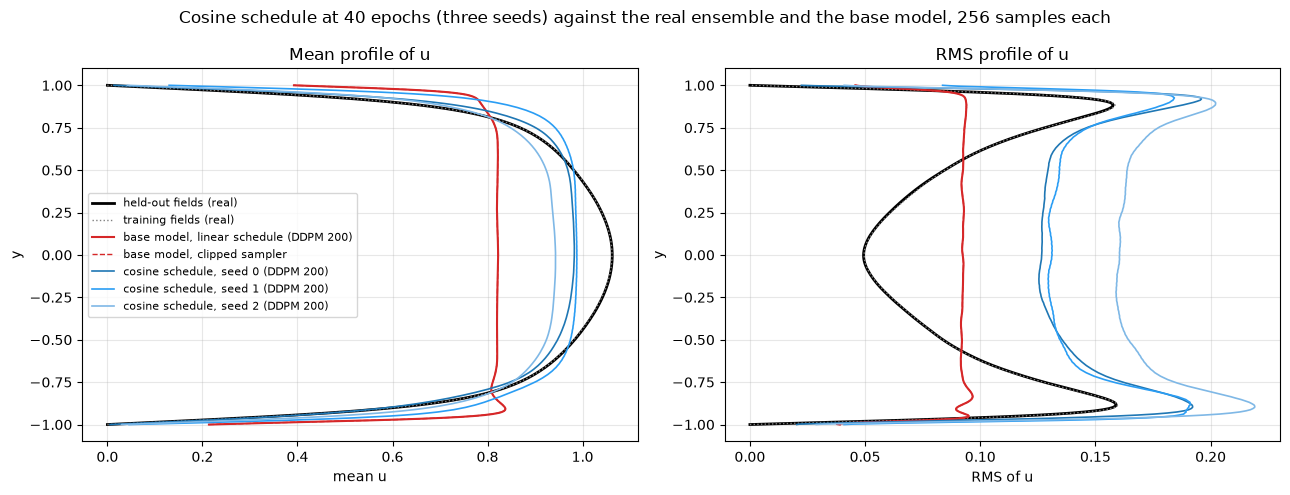

In [12]:
a = pd.DataFrame(rows); a.to_csv(RES / "a_statistics_runs.csv", index=False)
num = [c for c in a.columns if c not in ("ensemble", "seed", "n", "sample_s", "model_seed", "train_min", "final_loss")]
ta = a.groupby("ensemble", sort=False)[num].agg(["median", "min", "max"]); ta.to_csv(RES / "a_statistics_table.csv")
pd.set_option("display.width", 250)
print("Median over seeds (training fields and base model: one value)")
print(a.groupby("ensemble", sort=False)[num].median().T.round(4).to_string())

# Earlier run (Stage 2): base model with three sampling seeds
try:
    earlier = pd.read_csv(EARLIER_STAGE / "a_statistics_table.csv", header=[0, 1], index_col=0)
    eb = earlier.loc["diffusion (DDPM, 200 steps)"]
    print("\nEarlier run of the base model (Stage 2, 3 sampling seeds): mean-profile MAE "
          f"{eb[('mean_profile_mae', 'mean')]:.4f} [{eb[('mean_profile_mae', 'min')]:.4f}, {eb[('mean_profile_mae', 'max')]:.4f}], "
          f"RMS-profile MAE {eb[('rms_profile_mae', 'mean')]:.4f} [{eb[('rms_profile_mae', 'min')]:.4f}, {eb[('rms_profile_mae', 'max')]:.4f}], "
          f"spectral distance y+15 {eb[('spectral_distance_y15', 'mean')]:.3f}")
except Exception as e:
    print("Stage 2 table not read:", e)

cos = a[a.ensemble == "cosine, DDPM 200 clipped"]; base_row = a[a.ensemble == "base model, linear, DDPM 200"].iloc[0]; base_clip = a[a.ensemble == "base model, linear, DDPM 200 clipped"].iloc[0]
ref_real = a[a.ensemble == "training fields (real)"].iloc[0]
verdict = []
for stat in ("mean_profile_mae", "rms_profile_mae", "spectral_distance_y15", "spectral_distance_all_rows", "corr_mae_y15", "pdf_wasserstein_y15"):
    c = cos[stat]; rng_ = c.max() - c.min(); med = c.median()
    beats = bool((c.max() < base_row[stat]) and ((base_row[stat] - med) > rng_)); beats_clip = bool((c.max() < base_clip[stat]) and ((base_clip[stat] - med) > rng_))
    worse = bool((c.min() > base_row[stat]) and ((med - base_row[stat]) > rng_))
    verdict.append(dict(statistic=stat, cosine_median=med, cosine_min=c.min(), cosine_max=c.max(), base_model=base_row[stat], base_model_clipped=base_clip[stat],
                        real_to_real=ref_real[stat], cosine_beats_base=beats, cosine_beats_base_clipped=beats_clip, cosine_worse_than_base=worse,
                        gap_closed=bool(c.max() <= 2 * ref_real[stat] + 1e-9)))
v = pd.DataFrame(verdict); v.to_csv(RES / "a_verdict.csv", index=False); print("\n" + v.round(4).to_string(index=False))
mp = v[v.statistic == "mean_profile_mae"].iloc[0]
print(f"\nResult (a): mean-profile MAE cosine {mp.cosine_median:.4f} [{mp.cosine_min:.4f}, {mp.cosine_max:.4f}] vs base model {mp.base_model:.4f} (clipped sampler {mp.base_model_clipped:.4f}); "
      f"real-to-real {mp.real_to_real:.4f}. Beats the base model beyond the seed range: {mp.cosine_beats_base}; closes the gap (within twice the real-to-real level): {mp.gap_closed}")
print("training minutes per seed:", cos.train_min.round(1).tolist(), "| final losses:", cos.final_loss.round(4).tolist())

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].plot(curves[("held-out fields (real)", -1)]["mean"], y_grid, "k", lw=2, label="held-out fields (real)"); ax[1].plot(curves[("held-out fields (real)", -1)]["rms"], y_grid, "k", lw=2)
ax[0].plot(curves[("training fields (real)", -1)]["mean"], y_grid, color="0.5", ls=":", lw=1, label="training fields (real)"); ax[1].plot(curves[("training fields (real)", -1)]["rms"], y_grid, color="0.5", ls=":", lw=1)
ax[0].plot(curves[("base model, linear, DDPM 200", 0)]["mean"], y_grid, color="#d62728", lw=1.5, label="base model, linear schedule (DDPM 200)"); ax[1].plot(curves[("base model, linear, DDPM 200", 0)]["rms"], y_grid, color="#d62728", lw=1.5)
ax[0].plot(curves[("base model, linear, DDPM 200 clipped", 0)]["mean"], y_grid, color="#d62728", ls="--", lw=1, label="base model, clipped sampler"); ax[1].plot(curves[("base model, linear, DDPM 200 clipped", 0)]["rms"], y_grid, color="#d62728", ls="--", lw=1)
for seed, col in zip((0, 1, 2), ("#1f77b4", "#2a9df4", "#7fb8e6")):
    ax[0].plot(curves[("cosine, DDPM 200 clipped", seed)]["mean"], y_grid, color=col, lw=1.2, label=f"cosine schedule, seed {seed} (DDPM 200)"); ax[1].plot(curves[("cosine, DDPM 200 clipped", seed)]["rms"], y_grid, color=col, lw=1.2)
ax[0].set_xlabel("mean u"); ax[0].set_ylabel("y"); ax[1].set_xlabel("RMS of u"); ax[1].set_ylabel("y")
ax[0].set_title("Mean profile of u"); ax[1].set_title("RMS profile of u")
for a_ in ax: a_.grid(alpha=0.3)
ax[0].legend(fontsize=8); fig.suptitle("Cosine schedule at 40 epochs (three seeds) against the real ensemble and the base model, 256 samples each"); fig.tight_layout()
fig.savefig(RES / "a_profiles.png", dpi=130); plt.show()

## Part (b): a copying test with a calibrated distance

Distance of a field to the training set = RMS difference in u over the 201 × 384 points to the nearest of the 5,200 training fields. For a held-out field I compute it twice: over all training fields (Stage 2's number, which allows other planes of the same snapshot) and over the training fields of **different snapshots** only. The second is the distance a genuinely new field of this flow has from the training set, and the yardstick for the samples. The samples of the cosine model (768 by DDPM, three seeds) and of the base model (256 by DDPM, this run) get their nearest-training distance over all training fields.

                                               count    mean     std     min      1%      5%     50%     95%     max
ensemble                                                                                                            
held-out real fields, any training field       577.0  0.0266  0.0035  0.0183  0.0207  0.0220  0.0264  0.0313  0.0524
held-out real fields, different snapshot only  577.0  0.1092  0.0049  0.0898  0.0977  0.1016  0.1091  0.1177  0.1244
cosine model samples (DDPM 200 clipped)        768.0  0.1687  0.0175  0.1219  0.1326  0.1405  0.1689  0.1974  0.2235
base model samples (DDPM 200)                  256.0  0.2287  0.0038  0.2180  0.2197  0.2230  0.2286  0.2350  0.2387

held-out fields whose nearest training field (any) is from the same snapshot: 1.000
cosine samples: median nearest-training distance per seed [0.1501, 0.1697, 0.1843]; distinct nearest training fields 450 of 768 samples; share closer than the closest held-out field of a different snapshot (0.0898

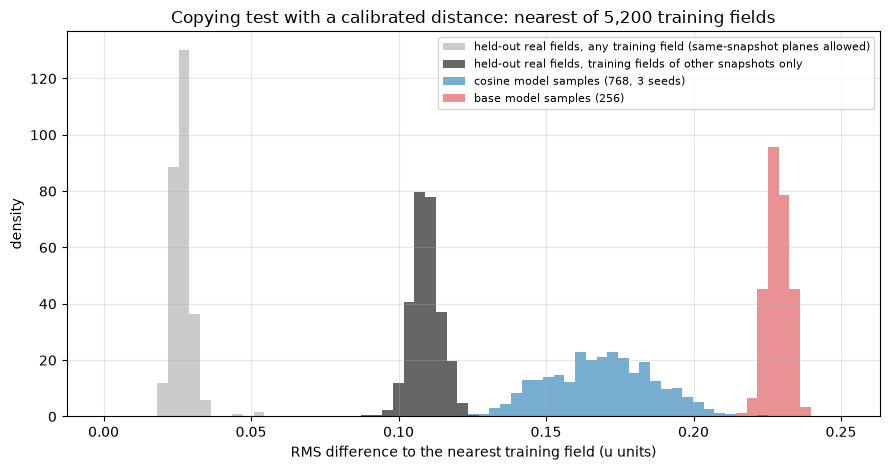

In [13]:
TR = train.reshape(len(train), -1).astype(np.float32); tr_sq = (TR ** 2).sum(1); snap_tr = snap[trn_idx]
def nn_dist(U, exclude_snap=None, chunk=64):
    d, j = np.zeros(len(U)), np.zeros(len(U), int)
    for s in range(0, len(U), chunk):
        Q = U[s:s + chunk].reshape(-1, TR.shape[1]).astype(np.float32); d2 = (Q ** 2).sum(1)[:, None] + tr_sq[None, :] - 2.0 * Q @ TR.T
        if exclude_snap is not None: d2[snap_tr[None, :] == exclude_snap[s:s + chunk, None]] = np.inf
        jj = np.argmin(d2, axis=1); d[s:s + chunk] = np.sqrt(np.maximum(d2[np.arange(len(Q)), jj], 0) / Q.shape[1]); j[s:s + chunk] = jj
    return d, j

nn_rows = []
d_same, j_same = nn_dist(held); d_diff, j_diff = nn_dist(held, exclude_snap=snap[val_idx])
nn_rows += [dict(ensemble="held-out real fields, any training field", seed=-1, i=i, nn_rms=float(v), nn_index=int(trn_idx[j]), same_snapshot=bool(snap_tr[j] == snap[val_idx][i])) for i, (v, j) in enumerate(zip(d_same, j_same))]
nn_rows += [dict(ensemble="held-out real fields, different snapshot only", seed=-1, i=i, nn_rms=float(v), nn_index=int(trn_idx[j]), same_snapshot=False) for i, (v, j) in enumerate(zip(d_diff, j_diff))]
for seed in (0, 1, 2):
    dg, jg = nn_dist(samples[("cosine, DDPM 200 clipped", seed)])
    nn_rows += [dict(ensemble="cosine model samples (DDPM 200 clipped)", seed=seed, i=i, nn_rms=float(v), nn_index=int(trn_idx[j]), same_snapshot=False) for i, (v, j) in enumerate(zip(dg, jg))]
db, jb = nn_dist(samples[("base model, linear, DDPM 200", 0)])
nn_rows += [dict(ensemble="base model samples (DDPM 200)", seed=0, i=i, nn_rms=float(v), nn_index=int(trn_idx[j]), same_snapshot=False) for i, (v, j) in enumerate(zip(db, jb))]
nn = pd.DataFrame(nn_rows); nn.to_csv(RES / "b_nearest_training_distance.csv", index=False)
q = nn.groupby("ensemble", sort=False).nn_rms.describe(percentiles=[0.01, 0.05, 0.5, 0.95]); q.to_csv(RES / "b_nearest_distance_quantiles.csv"); print(q.round(4).to_string())
same_share = np.mean([r["same_snapshot"] for r in nn_rows if r["ensemble"].endswith("any training field")])
print(f"\nheld-out fields whose nearest training field (any) is from the same snapshot: {same_share:.3f}")
cosd = nn[nn.ensemble.str.startswith("cosine")]
per_seed = cosd.groupby("seed").nn_rms.median()
print(f"cosine samples: median nearest-training distance per seed {per_seed.round(4).tolist()}; distinct nearest training fields {cosd.nn_index.nunique()} of {len(cosd)} samples; "
      f"share closer than the closest held-out field of a different snapshot ({d_diff.min():.4f}): {np.mean(cosd.nn_rms < d_diff.min()):.3f}; "
      f"share within the held-out different-snapshot range [{d_diff.min():.4f}, {d_diff.max():.4f}]: {np.mean((cosd.nn_rms >= d_diff.min()) & (cosd.nn_rms <= d_diff.max())):.3f}")
try:
    eq = pd.read_csv(EARLIER_STAGE / "b_nearest_distance_quantiles.csv", index_col=0)
    print("earlier run (Stage 2) medians: held-out (any training field)", round(float(eq.loc["held-out real fields", "50%"]), 4), "| base model samples", round(float(eq.loc["diffusion samples", "50%"]), 4))
except Exception as e:
    print("Stage 2 quantiles not read:", e)
print(f"\nResult (b): a new field of this flow lies {np.median(d_diff):.4f} [{d_diff.min():.4f}, {d_diff.max():.4f}] from the training set (different snapshot), "
      f"against {np.median(d_same):.4f} [{d_same.min():.4f}, {d_same.max():.4f}] when same-snapshot planes count; cosine samples {cosd.nn_rms.median():.4f} [{cosd.nn_rms.min():.4f}, {cosd.nn_rms.max():.4f}]; "
      f"base model samples {np.median(db):.4f} [{db.min():.4f}, {db.max():.4f}]")

fig, ax = plt.subplots(figsize=(9, 4.8))
bins = np.linspace(0, nn.nn_rms.max() * 1.05, 70)
ax.hist(d_same, bins=bins, density=True, alpha=0.5, color="0.6", label="held-out real fields, any training field (same-snapshot planes allowed)")
ax.hist(d_diff, bins=bins, density=True, alpha=0.6, color="k", label="held-out real fields, training fields of other snapshots only")
ax.hist(cosd.nn_rms, bins=bins, density=True, alpha=0.6, color="#1f77b4", label="cosine model samples (768, 3 seeds)")
ax.hist(db, bins=bins, density=True, alpha=0.5, color="#d62728", label="base model samples (256)")
ax.set_xlabel("RMS difference to the nearest training field (u units)"); ax.set_ylabel("density"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
ax.set_title("Copying test with a calibrated distance: nearest of 5,200 training fields"); fig.tight_layout(); fig.savefig(RES / "b_calibrated_copying.png", dpi=130); plt.show()

## Record of the run

In [14]:
summary = dict(fields=int(len(fields)), training=int(len(train)), held_out=int(len(held)), data_mean=float(data_mean), data_std=float(data_std), T=T, epochs=40,
               clip=CLIP, device=DEVICE, train_min_per_seed=cos.train_min.round(2).tolist(), final_loss_per_seed=cos.final_loss.round(5).tolist(),
               longest_training_min=float(cos.train_min.max()), verdict=v.to_dict("records"), nearest_quantiles=q.reset_index().to_dict("records"),
               wall_min=round((time.time() - T_START) / 60, 1), tensorflow=tf.__version__, keras=tf.keras.__version__)
json.dump(summary, open(RES / "run_summary.json", "w"), indent=1, default=float)
print(f"longest single training {summary['longest_training_min']:.1f} min; notebook wall time {summary['wall_min']:.1f} min")

longest single training 19.2 min; notebook wall time 62.3 min
